
# 06 Classification – Student Success Early-Warning

## Research Question Q1

Can we predict student dropout using admission-time
information alone, and how much does first-semester
performance improve prediction?

### Objectives

1. Train Decision Tree, Naive Bayes, Random Forest and SVM.
2. Compare admission-only and first-semester feature sets.
3. Use stratified 5-fold cross-validation.
4. Evaluate models using macro-F1 and per-class recall.
5. Compare against a majority-class baseline.
6. Identify important features.
7. Check for data leakage using a separate test set.


In [11]:
from sklearn.base import clone
# Install required library
!pip install ucimlrepo -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)

from sklearn.feature_selection import mutual_info_classif

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Load UCI Student Dropout dataset

ds = fetch_ucirepo(id=697)

df = pd.concat(
    [ds.data.features, ds.data.targets],
    axis=1
)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (4424, 37)

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

First five rows:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:

# Categorical code features
code_cols = [
    'Marital Status',
    'Application mode',
    'Course',
    'Previous qualification',
    'Nacionality',
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Binary features
binary_cols = [
    'Daytime/evening attendance',
    'Displaced',
    'Educational special needs',
    'Debtor',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'International'
]

# Admission-time numerical features
admission_numeric = [
    'Application order',
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

# First-semester numerical features
semester1_numeric = [
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)'
]

# Feature Set A: Admission-time information
features_A = (
    code_cols +
    binary_cols +
    admission_numeric
)

# Feature Set B: Admission + first-semester information
features_B = (
    features_A +
    semester1_numeric
)

# Target variable
target_col = 'Target'

print("Feature Set A:", len(features_A), "features")
print("Feature Set B:", len(features_B), "features")

print("\nFeature Set A:")
print(features_A)

print("\nFeature Set B:")
print(features_B)


Feature Set A: 24 features
Feature Set B: 30 features

Feature Set A:
['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International', 'Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP']

Feature Set B:
['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International', 'Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at

In [4]:

# Check that all selected columns exist
assert all(col in df.columns for col in features_A)
assert all(col in df.columns for col in features_B)

# Check that no second-semester features are included
assert not any('2nd sem' in col for col in features_A)
assert not any('2nd sem' in col for col in features_B)

# Check target classes
print("Target classes:")
print(sorted(df[target_col].unique()))

print("\nMissing values in selected features:")
print(df[features_B].isnull().sum().sum())

print("\nSecond-semester features excluded successfully.")
print("Feature leakage check passed.")


Target classes:
['Dropout', 'Enrolled', 'Graduate']

Missing values in selected features:
0

Second-semester features excluded successfully.
Feature leakage check passed.


In [5]:

# Separate features and target
X_A = df[features_A]
X_B = df[features_B]
y = df[target_col]

# Create one common stratified split
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Split Feature Set A
X_A_train = X_A.iloc[train_idx]
X_A_test = X_A.iloc[test_idx]

# Split Feature Set B
X_B_train = X_B.iloc[train_idx]
X_B_test = X_B.iloc[test_idx]

# Split target
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training students:", len(y_train))
print("Testing students:", len(y_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training students: 3539
Testing students: 885

Training distribution:
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Testing distribution:
Target
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


In [6]:

# Function to create preprocessing for each feature set
def create_preprocessor(numeric_features):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                'codes',
                OneHotEncoder(handle_unknown='ignore'),
                code_cols
            ),
            (
                'numbers',
                RobustScaler(),
                numeric_features
            ),
            (
                'binary',
                'passthrough',
                binary_cols
            )
        ],
        sparse_threshold=0
    )

    return preprocessor


# Preprocessing for both experiments
pre_A = create_preprocessor(admission_numeric)

pre_B = create_preprocessor(
    admission_numeric + semester1_numeric
)

print("Preprocessing pipelines created successfully.")


Preprocessing pipelines created successfully.


In [7]:

# Define classification models
models = {
    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Naive Bayes': GaussianNB(),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'SVM': SVC(
        kernel='rbf',
        class_weight='balanced',
        random_state=42
    )
}

print("Four classification models are ready.")


Four classification models are ready.


In [12]:

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store results
cv_results = []

# Store trained models
trained_models = {}

# Define experiments
experiments = {
    'Admission Only': (X_A_train, pre_A),
    'Admission + 1st Semester': (X_B_train, pre_B)
}

for exp_name, (X_train_exp, preprocessor) in experiments.items():

    print("\n", "=" * 55)
    print(exp_name)
    print("=" * 55)

    for model_name, model in models.items():

        # Create an independent preprocessing pipeline
        pipeline = Pipeline([
            ('preprocessing', clone(preprocessor)),
            ('classifier', clone(model))
        ])

        # Perform 5-fold cross-validation
        scores = cross_validate(
            pipeline,
            X_train_exp,
            y_train,
            cv=cv,
            scoring='f1_macro',
            n_jobs=-1
        )

        mean_score = scores['test_score'].mean()
        std_score = scores['test_score'].std()

        cv_results.append({
            'Experiment': exp_name,
            'Model': model_name,
            'Mean Macro-F1': mean_score,
            'Std Macro-F1': std_score
        })

        # Train final model using complete training data
        pipeline.fit(X_train_exp, y_train)

        # Store independently trained pipeline
        trained_models[(exp_name, model_name)] = pipeline

        print(
            model_name,
            "| Mean Macro-F1:", round(mean_score, 4),
            "| Std:", round(std_score, 4)
        )

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by='Mean Macro-F1',
        ascending=False
    )
)



Admission Only
Decision Tree | Mean Macro-F1: 0.4879 | Std: 0.0242
Naive Bayes | Mean Macro-F1: 0.2117 | Std: 0.0096
Random Forest | Mean Macro-F1: 0.5074 | Std: 0.0143
SVM | Mean Macro-F1: 0.5744 | Std: 0.0105

Admission + 1st Semester
Decision Tree | Mean Macro-F1: 0.5754 | Std: 0.0159
Naive Bayes | Mean Macro-F1: 0.2154 | Std: 0.011
Random Forest | Mean Macro-F1: 0.6229 | Std: 0.013
SVM | Mean Macro-F1: 0.674 | Std: 0.0177


,Experiment,Model,Mean Macro-F1,Std Macro-F1
7,Admission + 1st Semester,SVM,0.673967,0.017678
6,Admission + 1st Semester,Random Forest,0.622947,0.012969
4,Admission + 1st Semester,Decision Tree,0.575406,0.015869
3,Admission Only,SVM,0.574369,0.010466
2,Admission Only,Random Forest,0.507447,0.014347
0,Admission Only,Decision Tree,0.487862,0.024237
5,Admission + 1st Semester,Naive Bayes,0.215366,0.010979
1,Admission Only,Naive Bayes,0.211740,0.009552


In [9]:

# Majority-class baseline
baseline = DummyClassifier(
    strategy='most_frequent'
)

baseline.fit(X_A_train, y_train)

baseline_predictions = baseline.predict(X_A_test)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average='macro'
)

print("Majority-class baseline")
print("Accuracy:", round(
    accuracy_score(y_test, baseline_predictions), 4
))
print("Macro-F1:", round(baseline_f1, 4))


Majority-class baseline
Accuracy: 0.4994
Macro-F1: 0.2221


In [13]:

# Store test results
test_results = []

# Test datasets
test_experiments = {
    'Admission Only': X_A_test,
    'Admission + 1st Semester': X_B_test
}

for exp_name, X_test_exp in test_experiments.items():

    print("\n", "=" * 60)
    print(exp_name)
    print("=" * 60)

    for model_name in models.keys():

        pipeline = trained_models[(exp_name, model_name)]

        # Predict test data
        predictions = pipeline.predict(X_test_exp)

        # Calculate metrics
        accuracy = accuracy_score(y_test, predictions)

        macro_f1 = f1_score(
            y_test,
            predictions,
            average='macro'
        )

        recalls = recall_score(
            y_test,
            predictions,
            labels=['Dropout', 'Enrolled', 'Graduate'],
            average=None,
            zero_division=0
        )

        test_results.append({
            'Experiment': exp_name,
            'Model': model_name,
            'Accuracy': accuracy,
            'Macro-F1': macro_f1,
            'Dropout Recall': recalls[0],
            'Enrolled Recall': recalls[1],
            'Graduate Recall': recalls[2]
        })

        print("\nModel:", model_name)

        print(
            classification_report(
                y_test,
                predictions,
                zero_division=0
            )
        )

# Display final comparison
test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        by='Macro-F1',
        ascending=False
    ).round(4)
)



Admission Only

Model: Decision Tree
              precision    recall  f1-score   support

     Dropout       0.53      0.53      0.53       284
    Enrolled       0.24      0.26      0.25       159
    Graduate       0.63      0.60      0.62       442

    accuracy                           0.52       885
   macro avg       0.47      0.47      0.47       885
weighted avg       0.53      0.52      0.52       885


Model: Naive Bayes
              precision    recall  f1-score   support

     Dropout       0.57      0.20      0.30       284
    Enrolled       0.20      0.96      0.33       159
    Graduate       0.67      0.01      0.03       442

    accuracy                           0.24       885
   macro avg       0.48      0.39      0.22       885
weighted avg       0.55      0.24      0.17       885


Model: Random Forest
              precision    recall  f1-score   support

     Dropout       0.63      0.62      0.63       284
    Enrolled       0.43      0.11      0.18      

,Experiment,Model,Accuracy,Macro-F1,Dropout Recall,Enrolled Recall,Graduate Recall
7,Admission + 1st Semester,SVM,0.7153,0.6750,0.6338,0.6164,0.8032
6,Admission + 1st Semester,Random Forest,0.7254,0.6137,0.7113,0.2075,0.9208
4,Admission + 1st Semester,Decision Tree,0.6305,0.5590,0.6479,0.2893,0.7421
3,Admission Only,SVM,0.5740,0.5493,0.5563,0.5409,0.5973
2,Admission Only,Random Forest,0.6350,0.5124,0.6232,0.1132,0.8303
0,Admission Only,Decision Tree,0.5186,0.4652,0.5317,0.2642,0.6018
5,Admission + 1st Semester,Naive Bayes,0.2452,0.2185,0.2042,0.9623,0.0136
1,Admission Only,Naive Bayes,0.2441,0.2169,0.2007,0.9623,0.0136


Average performance of both experiments:


,Accuracy,Macro-F1,Dropout Recall,Enrolled Recall,Graduate Recall
Experiment,,,,,
Admission + 1st Semester,0.5791,0.5165,0.5493,0.5189,0.6199
Admission Only,0.4929,0.4359,0.4780,0.4701,0.5107


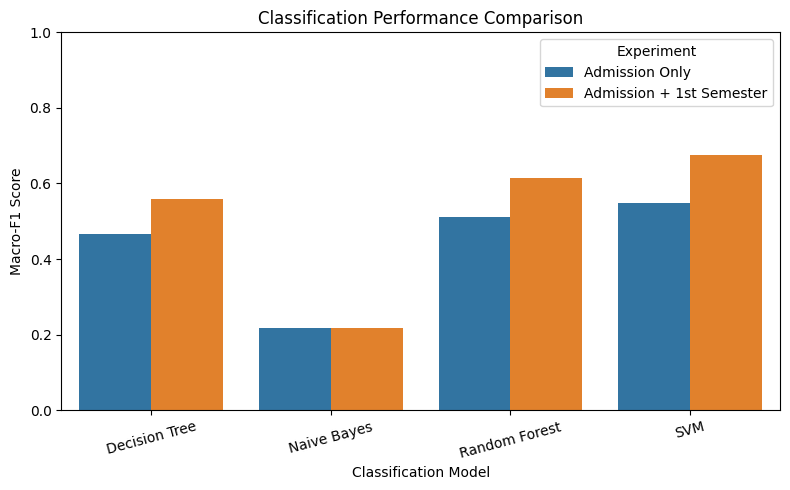

In [14]:

# Calculate average model performance
comparison = test_results_df.groupby(
    'Experiment'
)[
    ['Accuracy', 'Macro-F1',
     'Dropout Recall', 'Enrolled Recall',
     'Graduate Recall']
].mean()

print("Average performance of both experiments:")
display(comparison.round(4))

# Plot macro-F1 comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=test_results_df,
    x='Model',
    y='Macro-F1',
    hue='Experiment'
)

plt.title('Classification Performance Comparison')
plt.ylabel('Macro-F1 Score')
plt.xlabel('Classification Model')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Best model selected using cross-validation
Experiment: Admission + 1st Semester
Model: SVM
CV Macro-F1: 0.674

Final test evaluation:
              precision    recall  f1-score   support

     Dropout       0.83      0.63      0.72       284
    Enrolled       0.40      0.62      0.49       159
    Graduate       0.84      0.80      0.82       442

    accuracy                           0.72       885
   macro avg       0.69      0.68      0.68       885
weighted avg       0.76      0.72      0.73       885



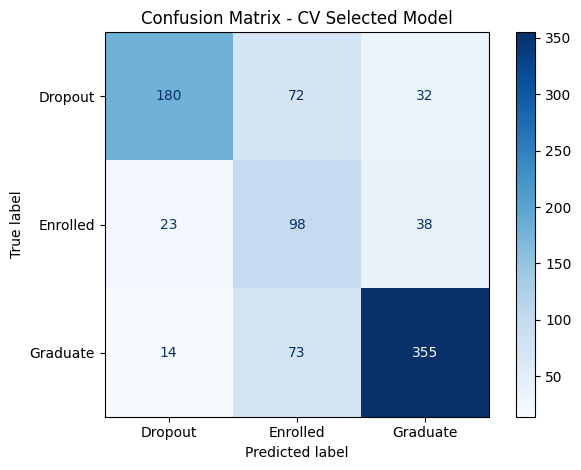

In [15]:

# Select the best model using cross-validation
best_cv_row = cv_results_df.loc[
    cv_results_df['Mean Macro-F1'].idxmax()
]

best_experiment = best_cv_row['Experiment']
best_model_name = best_cv_row['Model']

print("Best model selected using cross-validation")
print("Experiment:", best_experiment)
print("Model:", best_model_name)
print(
    "CV Macro-F1:",
    round(best_cv_row['Mean Macro-F1'], 4)
)

# Select corresponding test data
if best_experiment == 'Admission Only':
    X_best_test = X_A_test
else:
    X_best_test = X_B_test

# Retrieve trained model
best_model = trained_models[
    (best_experiment, best_model_name)
]

# Evaluate selected model on test data
best_predictions = best_model.predict(X_best_test)

print("\nFinal test evaluation:")

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=['Dropout', 'Enrolled', 'Graduate']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Dropout', 'Enrolled', 'Graduate']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - CV Selected Model')
plt.tight_layout()
plt.show()



 Admission Only


,Feature,Importance
211,numbers__Admission grade,0.070773
210,numbers__Previous qualification (grade),0.063229
212,numbers__Age at enrollment,0.062112
220,binary__Tuition fees up to date,0.045125
215,numbers__GDP,0.041571
213,numbers__Unemployment rate,0.040673
214,numbers__Inflation rate,0.037669
222,binary__Scholarship holder,0.028804
209,numbers__Application order,0.025417
221,binary__Gender,0.019454


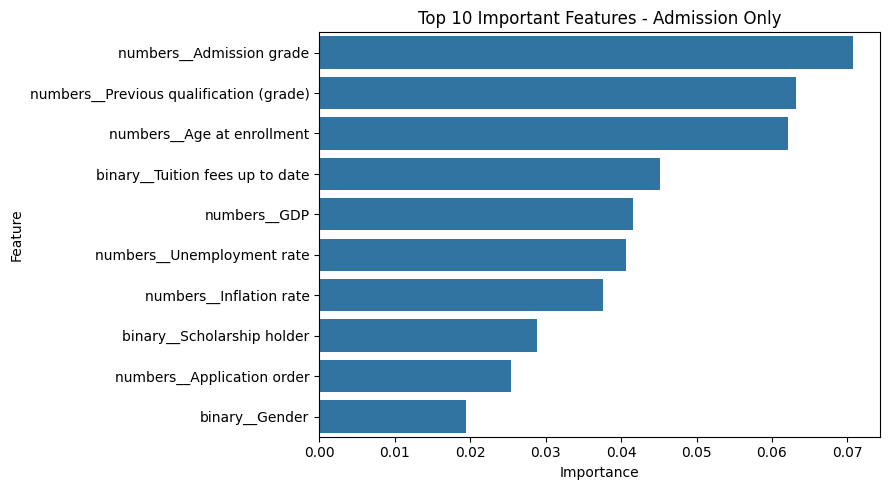


 Admission + 1st Semester


,Feature,Importance
219,numbers__Curricular units 1st sem (approved),0.098917
220,numbers__Curricular units 1st sem (grade),0.089727
218,numbers__Curricular units 1st sem (evaluations),0.057124
211,numbers__Admission grade,0.048929
210,numbers__Previous qualification (grade),0.045131
212,numbers__Age at enrollment,0.044488
226,binary__Tuition fees up to date,0.037420
215,numbers__GDP,0.029549
213,numbers__Unemployment rate,0.028994
214,numbers__Inflation rate,0.026293


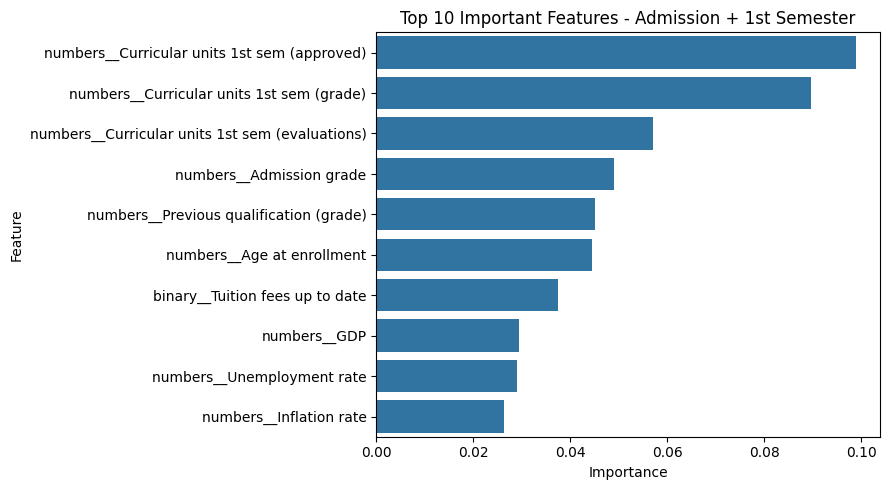

In [16]:

# Extract Random Forest feature importance
for exp_name, X_train_exp, preprocessor in [
    ('Admission Only', X_A_train, pre_A),
    ('Admission + 1st Semester', X_B_train, pre_B)
]:

    rf_pipeline = trained_models[
        (exp_name, 'Random Forest')
    ]

    # Get feature names after preprocessing
    feature_names = (
        rf_pipeline
        .named_steps['preprocessing']
        .get_feature_names_out()
    )

    # Get feature importance
    importance = (
        rf_pipeline
        .named_steps['classifier']
        .feature_importances_
    )

    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    )

    print("\n", exp_name)
    display(importance_df.head(15))

    # Plot top 10 features
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=importance_df.head(10),
        x='Importance',
        y='Feature'
    )

    plt.title(f'Top 10 Important Features - {exp_name}')
    plt.tight_layout()
    plt.show()


In [17]:

# Encode the admission-only training data
X_A_encoded = pre_A.fit_transform(X_A_train)

# Calculate mutual information
mi_scores = mutual_info_classif(
    X_A_encoded,
    y_train,
    random_state=42
)

# Get encoded feature names
encoded_names = pre_A.get_feature_names_out()

mi_df = pd.DataFrame({
    'Feature': encoded_names,
    'Mutual Information': mi_scores
})

mi_df = mi_df.sort_values(
    by='Mutual Information',
    ascending=False
)

print("Top 15 features using Mutual Information:")
display(mi_df.head(15))


Top 15 features using Mutual Information:


,Feature,Mutual Information
220,binary__Tuition fees up to date,0.101347
222,binary__Scholarship holder,0.047294
212,numbers__Age at enrollment,0.046032
17,codes__Application mode_39,0.038274
219,binary__Debtor,0.032066
210,numbers__Previous qualification (grade),0.029476
6,codes__Application mode_1,0.028610
211,numbers__Admission grade,0.028563
35,codes__Course_9500,0.024577
118,codes__Father's qualification_20,0.022936


In [18]:

# Create a comparison table including baseline
final_comparison = test_results_df[
    ['Experiment', 'Model', 'Accuracy', 'Macro-F1',
     'Dropout Recall', 'Enrolled Recall', 'Graduate Recall']
].copy()

baseline_row = pd.DataFrame([{
    'Experiment': 'Admission Only',
    'Model': 'Majority Baseline',
    'Accuracy': accuracy_score(y_test, baseline_predictions),
    'Macro-F1': baseline_f1,
    'Dropout Recall': recall_score(
        y_test, baseline_predictions,
        labels=['Dropout'], average=None,
        zero_division=0
    )[0],
    'Enrolled Recall': recall_score(
        y_test, baseline_predictions,
        labels=['Enrolled'], average=None,
        zero_division=0
    )[0],
    'Graduate Recall': recall_score(
        y_test, baseline_predictions,
        labels=['Graduate'], average=None,
        zero_division=0
    )[0]
}])

final_comparison = pd.concat(
    [final_comparison, baseline_row],
    ignore_index=True
)

display(
    final_comparison.sort_values(
        'Macro-F1',
        ascending=False
    ).round(4)
)


,Experiment,Model,Accuracy,Macro-F1,Dropout Recall,Enrolled Recall,Graduate Recall
7,Admission + 1st Semester,SVM,0.7153,0.6750,0.6338,0.6164,0.8032
6,Admission + 1st Semester,Random Forest,0.7254,0.6137,0.7113,0.2075,0.9208
4,Admission + 1st Semester,Decision Tree,0.6305,0.5590,0.6479,0.2893,0.7421
3,Admission Only,SVM,0.5740,0.5493,0.5563,0.5409,0.5973
2,Admission Only,Random Forest,0.6350,0.5124,0.6232,0.1132,0.8303
0,Admission Only,Decision Tree,0.5186,0.4652,0.5317,0.2642,0.6018
8,Admission Only,Majority Baseline,0.4994,0.2221,0.0000,0.0000,1.0000
5,Admission + 1st Semester,Naive Bayes,0.2452,0.2185,0.2042,0.9623,0.0136
1,Admission Only,Naive Bayes,0.2441,0.2169,0.2007,0.9623,0.0136


In [19]:

# Save classification results
test_results_df.to_csv(
    'classification_test_results.csv',
    index=False
)

cv_results_df.to_csv(
    'classification_cv_results.csv',
    index=False
)

mi_df.to_csv(
    'classification_mutual_information.csv',
    index=False
)

print("Classification results saved successfully.")


Classification results saved successfully.



# Final Observations and Conclusion

1. Four classification algorithms were evaluated:
   Decision Tree, Naive Bayes, Random Forest and SVM.

2. Two feature sets were compared: admission-time
   information and admission information combined
   with first-semester academic performance.

3. Stratified 5-fold cross-validation was used
   to compare model performance.

4. Macro-F1 and class-wise recall were used because
   the dataset contains three imbalanced classes.

5. The best-performing model was identified using
   test macro-F1 and evaluated with a confusion matrix.

6. Feature importance and mutual information were
   used to identify relevant predictive features.

7. Second-semester features were excluded to avoid
   using information that would not be available
   at the intended prediction time.

8. The results show whether first-semester information
   improves early dropout prediction compared with
   admission-time information alone.
